# 06 — Class balancing (Figure 6)

**Tujuan.** Bedakan imbalanced control dan balanced training. Paper §III-A/Figure 6 mengaitkan perbaikan metrik dengan augmentasi kelas, tetapi target per kelas tidak dijelaskan. Runner `balanced_v1` menggunakan train-only oversampling sampai jumlah draw kelas terbesar (`ASSUMED`); validation/test tetap asli. Grafik pertama adalah angka **PAPER_REFERENCE** saja.

In [1]:
from pathlib import Path
import os, sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "reproduction/cadvit/model.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
ARTIFACT_ROOT = Path(os.environ["CAD_VIT_ARTIFACT_ROOT"]).expanduser().resolve() if os.environ.get("CAD_VIT_ARTIFACT_ROOT") else None
print("Artifact root:", ARTIFACT_ROOT if ARTIFACT_ROOT else "PENDING (set CAD_VIT_ARTIFACT_ROOT)")

Artifact root: PENDING (set CAD_VIT_ARTIFACT_ROOT)


PAPER_REFERENCE Figure 6; order accuracy, precision, recall, F1
APTOS2019 {'imbalanced': (85.2, 85.7, 85.3, 85.3), 'balanced': (88.6, 88.4, 88.6, 88.4)}
DDR {'imbalanced': (81.6, 82.0, 81.6, 81.5), 'balanced': (84.8, 84.8, 84.8, 84.4)}


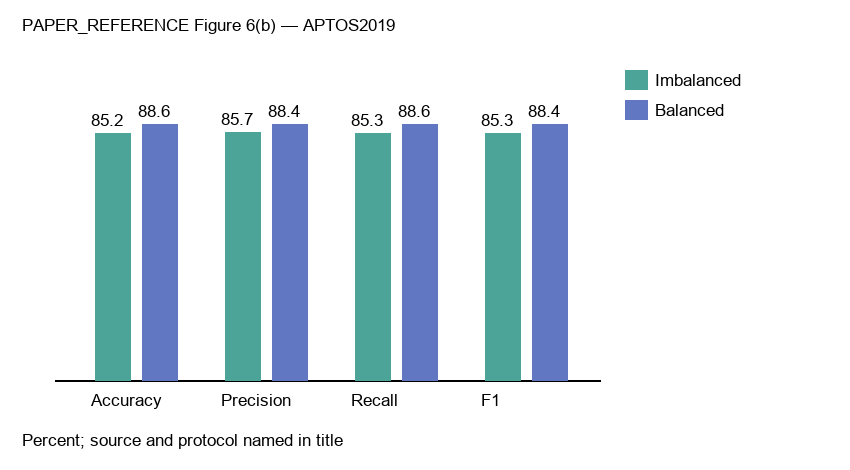

In [2]:
from reproduction.cadvit.visualization import PAPER_FIGURE_6, balance_metrics_png
print("PAPER_REFERENCE Figure 6; order accuracy, precision, recall, F1")
for dataset, values in PAPER_FIGURE_6.items():
    print(dataset, values)
balance_metrics_png(PAPER_FIGURE_6["APTOS2019"]["imbalanced"],
                    PAPER_FIGURE_6["APTOS2019"]["balanced"],
                    "PAPER_REFERENCE Figure 6(b) — APTOS2019")

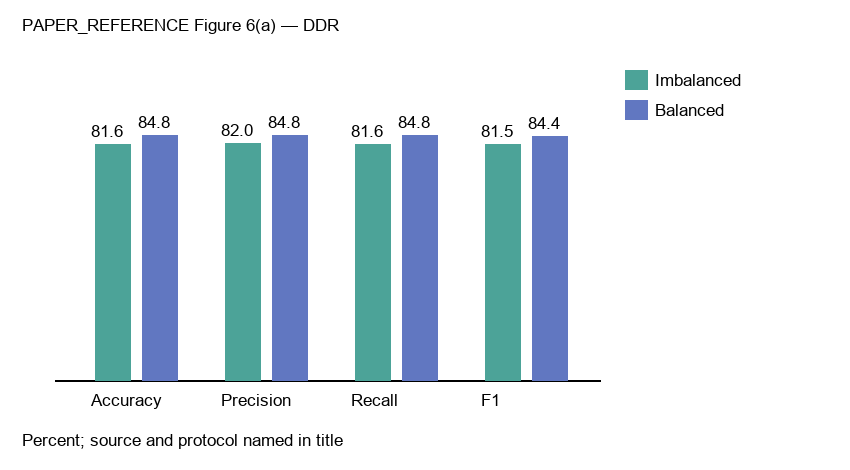

In [3]:
balance_metrics_png(PAPER_FIGURE_6["DDR"]["imbalanced"],
                    PAPER_FIGURE_6["DDR"]["balanced"],
                    "PAPER_REFERENCE Figure 6(a) — DDR")

In [4]:
from reproduction.cadvit.visualization import load_controlled_result, comparable_balancing_metrics
if ARTIFACT_ROOT:
    for dataset, variant in (("APTOS2019", "aptos_r16"), ("DDR", "ddr_full")):
        before = load_controlled_result(ARTIFACT_ROOT, "paper_v1", variant)
        after = load_controlled_result(ARTIFACT_ROOT, "balanced_v1", variant)
        print(dataset, "IMBALANCED_CONTROL", before["status"], "BALANCED_V1", after["status"])
        if after["status"] == "AVAILABLE":
            record = after["config"]
            print("train records:", record["train_class_counts_before"],
                  "draws per epoch:", record["train_class_counts_after"])
        if before["status"] == after["status"] == "AVAILABLE":
            try:
                pair = comparable_balancing_metrics(before, after)
                print("CONTROLLED_FINAL_TEST:", pair)
                from IPython.display import display
                display(balance_metrics_png(pair["imbalanced"], pair["balanced"],
                                            f'CONTROLLED_FINAL_TEST Figure 6 — {dataset}'))
            except ValueError as exc:
                print("UNRESOLVED comparison:", exc)
else:
    print("PENDING: campaign manifests/results unavailable; no experimental bars generated")

PENDING: campaign manifests/results unavailable; no experimental bars generated


In [5]:
from reproduction.cadvit.visualization import read_history, plot_training, plot_balance
from reproduction.cadvit.experiments import campaign_root, load_protocol, MODEL_SOURCE, PREPROCESS_SOURCE
from reproduction.cadvit.evaluation import file_sha256
from IPython.display import display
import json
if ARTIFACT_ROOT:
    for dataset, variant in (("APTOS2019", "aptos_r16"), ("DDR", "ddr_full")):
        for campaign in ("paper_v1", "balanced_v1"):
            run_dir = campaign_root(ARTIFACT_ROOT, campaign) / variant
            config_path = run_dir / "config.json"
            if not config_path.is_file():
                print(dataset, campaign, "PENDING config")
                continue
            record = json.loads(config_path.read_text(encoding="utf-8"))
            _, protocol_sha = load_protocol(ARTIFACT_ROOT, campaign)
            if (record.get("protocol_sha256") != protocol_sha
                    or record.get("variant", {}).get("name") != variant
                    or record.get("model_sha256") != file_sha256(MODEL_SOURCE)
                    or record.get("preprocessing_sha256") != file_sha256(PREPROCESS_SOURCE)):
                print(dataset, campaign, "UNRESOLVED source/config fingerprint")
                continue
            history = read_history(run_dir / "history.jsonl")
            print(dataset, campaign, history["status"],
                  "epochs", len(history.get("rows", [])), "history SHA-256", history.get("sha256", "PENDING"))
            if history["status"] == "AVAILABLE" and len(history["rows"]) >= 2:
                status = "80/80" if len(history["rows"]) == 80 else "PARTIAL"
                display(plot_training(history["rows"], f"{campaign} {dataset} {status}"))
            if campaign == "balanced_v1":
                before = record.get("train_class_counts_before")
                after = record.get("train_class_counts_after")
                if before and after:
                    display(plot_balance(before, after, f"BALANCED_V1 {dataset} train-only draws"))
else:
    print("PENDING training curves/distributions: local campaign logs and config unavailable")


PENDING training curves/distributions: local campaign logs and config unavailable


**Interpretasi dan batasan.** Paper Figure 6 tidak menentukan algoritma balancing. Perbandingan kampanye baru hanya sah jika manifest, preprocessing, model, seed, dan semua konfigurasi selain balancing identik. Grafik hasil kita tetap PENDING sampai kedua final-test JSON terverifikasi; test tidak dipakai untuk memilih strategi.